# Identificação do projeto

**Título do projeto:** Dengue no Brasil em 2026: pico de casos, gravidade e perfil dos pacientes

**Integrantes do grupo:** Bruna da Silva Carnelossi, João Pedro de Souza Quintiliano da Silva, João Victor Carvalho de Freitas, Matheus Henrique Heinzen

**Turma:** Sistemas de Informação, 6º período, Turma A GCL1, Profª Marina de Lara

**Descrição breve do problema ou contexto:** a dengue é a arbovirose de maior impacto no Brasil e todo caso suspeito tem notificação compulsória no SINAN. O projeto usa as notificações de 2026 para entender quando os casos se concentraram, onde e quais perfis de paciente evoluem para as formas graves. No RA3 fizemos a análise estatística do conjunto preparado no RA1, interpretamos os gráficos e testamos se dá para prever, no momento da notificação, quais pacientes vão ser hospitalizados.

Repositório: https://github.com/JoaoVictorCarvalho07/api-dados-abertos-saude

---

# RA3 – Análise, Visualização e Aprendizagem de Máquina

Utilize os dados preparados e processados nas etapas anteriores para realizar análises estatísticas, produzir visualizações, interpretar resultados e explorar uma aplicação simples de aprendizagem supervisionada.

## Preparação do ambiente

O RA3 usa o conjunto preparado no RA1 (`dados/preparados/dengue_brasil_2026.parquet`). Se o arquivo não existir, é preciso rodar antes o `ra1/ra1_dengue_2026.ipynb`. Usamos pandas, matplotlib e scikit-learn, com as versões fixadas no `requirements.txt`. A população por UF vem do Censo 2022 do IBGE (tabela SIDRA 4709) e está em `ra3/populacao_uf_censo2022.csv`. As figuras ficam salvas em `ra3/figuras/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

RAIZ = Path.cwd().parent
ARQUIVO_BRUTO = RAIZ / "DENGBR26.csv.zip"
ARQUIVO_PREPARADO = RAIZ / "dados" / "preparados" / "dengue_brasil_2026.parquet"
ARQUIVO_POPULACAO = RAIZ / "ra3" / "populacao_uf_censo2022.csv"
PASTA_FIGURAS = RAIZ / "ra3" / "figuras"
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

SEMENTE = 42
ATRASO_EXTREMO_DIAS = 60
SEMANAS_COM_ATRASO_DE_DIGITACAO = 4

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def milhar(numero):
    return f"{numero:,.0f}".replace(",", ".")


def percentual(parte, total):
    return f"{parte / total:.1%}".replace(".", ",")


if not ARQUIVO_PREPARADO.exists():
    raise FileNotFoundError("Execute antes o notebook do RA1 (ra1/ra1_dengue_2026.ipynb), que gera o Parquet preparado.")

df = pd.read_parquet(ARQUIVO_PREPARADO)
print(f"Conjunto preparado no RA1: {milhar(len(df))} notificações e {df.shape[1]} colunas")
print(f"Datas de notificação: {df['dt_notificacao'].min().date()} a {df['dt_notificacao'].max().date()}")

Conjunto preparado no RA1: 470.221 notificações e 24 colunas
Datas de notificação: 2026-01-04 a 2026-10-04


## 3.1 – Análise Estatística Descritiva

- Aplique medidas de tendência central, como média e/ou mediana.
- Investigue a dispersão dos dados com amplitude, desvio-padrão ou outras medidas adequadas.
- Analise a distribuição dos valores.
- Interprete os resultados no contexto do problema escolhido.

Escolhemos as duas variáveis numéricas mais importantes para o projeto. A primeira é a **idade** do paciente e a segunda é o **atraso entre o início dos sintomas e a notificação**, em dias. Para cada uma calculamos média, mediana e moda (tendência central), desvio-padrão, amplitude e intervalo interquartil (dispersão), e quartis e assimetria para ver a forma da distribuição. Depois contamos as categorias das variáveis ligadas à gravidade: classificação final, hospitalização e faixa etária.

In [2]:
def medidas(serie):
    valores = serie.dropna().astype(float)
    q1, q3 = valores.quantile([0.25, 0.75])
    return {
        "n válidos": len(valores),
        "média": valores.mean(),
        "mediana": valores.median(),
        "moda": valores.mode().iloc[0],
        "desvio-padrão": valores.std(),
        "mínimo": valores.min(),
        "Q1 (25%)": q1,
        "Q3 (75%)": q3,
        "IQR (Q3 - Q1)": q3 - q1,
        "máximo": valores.max(),
        "amplitude": valores.max() - valores.min(),
        "assimetria": valores.skew(),
    }


atraso = df["atraso_notificacao_dias"]
tabela_medidas = pd.DataFrame(
    {
        "idade (anos)": medidas(df["idade_anos"]),
        "atraso sintomas → notificação (dias)": medidas(atraso),
        f"atraso até {ATRASO_EXTREMO_DIAS} dias": medidas(atraso.where(atraso <= ATRASO_EXTREMO_DIAS)),
    }
)
display(tabela_medidas)

extremos = int((atraso > ATRASO_EXTREMO_DIAS).sum())
print(f"Atrasos acima de {ATRASO_EXTREMO_DIAS} dias: {milhar(extremos)} ({percentual(extremos, atraso.notna().sum())} dos atrasos válidos)")
print(f"Notificadas no mesmo dia dos sintomas ou até 7 dias depois: {percentual(int((atraso <= 7).sum()), atraso.notna().sum())}")

,idade (anos),atraso sintomas → notificação (dias),atraso até 60 dias
n válidos,"470,206.00","470,221.00","467,779.00"
média,31.64,4.51,4.04
mediana,29.00,3.00,3.00
moda,19.00,3.00,3.00
desvio-padrão,19.15,8.63,5.20
mínimo,0.00,0.00,0.00
Q1 (25%),17.00,1.00,1.00
Q3 (75%),44.00,5.00,5.00
IQR (Q3 - Q1),27.00,4.00,4.00
máximo,120.00,238.00,60.00


Atrasos acima de 60 dias: 2.442 (0,5% dos atrasos válidos)
Notificadas no mesmo dia dos sintomas ou até 7 dias depois: 89,3%


In [3]:
def frequencia(coluna, incluir_vazio=True):
    contagem = df[coluna].astype("object").fillna("(não informado)") if incluir_vazio else df[coluna].dropna()
    contagem = contagem.value_counts()
    return pd.DataFrame({"notificações": contagem, "%": contagem / contagem.sum() * 100})


print("Classificação final")
display(frequencia("classificacao_final"))
print("Hospitalização")
display(frequencia("hospitalizado"))
print("Faixa etária")
display(frequencia("faixa_etaria").reindex(list(df["faixa_etaria"].cat.categories) + ["(não informado)"]).dropna())

confirmados = df[df["caso_grave"].notna()]
print(f"Entre os {milhar(len(confirmados))} casos confirmados de dengue (10, 11 e 12), "
      f"{percentual(int(confirmados['caso_grave'].sum()), len(confirmados))} são graves ou com sinais de alarme.")
hosp_info = df["hospitalizado"].dropna()
print(f"Entre as {milhar(len(hosp_info))} notificações com hospitalização informada, "
      f"{percentual(int(hosp_info.sum()), len(hosp_info))} foram hospitalizadas.")

Classificação final


,notificações,%
classificacao_final,,
Dengue,352663,75.00
Inconclusivo,69873,14.86
Sem classificação,34829,7.41
Dengue com sinais de alarme,12076,2.57
Dengue grave,780,0.17


Hospitalização


,notificações,%
hospitalizado,,
False,316933,67.40
(não informado),123598,26.29
True,29690,6.31


Faixa etária


,notificações,%
faixa_etaria,,
0-4,24882,5.29
5-14,67477,14.35
15-29,150538,32.01
30-44,110264,23.45
45-59,71703,15.25
60-74,34876,7.42
75+,10466,2.23
(não informado),15,0.00


Entre os 365.519 casos confirmados de dengue (10, 11 e 12), 3,5% são graves ou com sinais de alarme.


Entre as 346.623 notificações com hospitalização informada, 8,6% foram hospitalizadas.


**Resposta do grupo:**

A idade média é 31,6 anos e a mediana é 29 anos. Metade dos pacientes tem entre 17 e 44 anos, um IQR de 27 anos. O desvio-padrão de 19,2 anos e a amplitude de 0 a 120 anos mostram que a dengue pega todas as idades. A distribuição tem uma leve assimetria à direita (0,55), porque os idosos formam uma cauda que puxa a média para cima da mediana. A faixa com mais notificações é a de 15 a 29 anos (32,0%), seguida pela de 30 a 44 anos (23,5%). Em 2026 a dengue atingiu principalmente adultos jovens.

No atraso até a notificação a diferença entre média e mediana é maior. A mediana é de 3 dias e o IQR vai de 1 a 5 dias, mas a média sobe para 4,5 dias, o desvio-padrão é de 8,6 dias e a amplitude chega a 238 dias. A assimetria de 9,2 é muito forte. 89,3% dos casos são notificados em até 7 dias, e só 2.442 registros (0,5%) passam de 60 dias. No RA1 já tínhamos marcado esses casos como prováveis erros de digitação ou notificações tardias. Mesmo tirando esses extremos a assimetria continua alta (4,6).

Por isso usamos a mediana e o IQR como medidas principais. Nas duas variáveis a média é puxada pela cauda (idosos e atrasos muito longos), e a mediana e o IQR quase não mudam com poucos valores extremos. A média e o desvio-padrão ficaram como complemento, e a diferença entre eles e a mediana mostra o tamanho da cauda.

Sobre gravidade, 75,0% das notificações foram classificadas como dengue, 14,9% como inconclusivas e 7,4% ainda estão sem classificação. Dos 365.519 casos confirmados, 3,5% tiveram dengue com sinais de alarme ou dengue grave. A hospitalização está preenchida em 346.623 notificações e 8,6% delas foram hospitalizadas. Em 26,3% das notificações esse campo está vazio.

Para o problema do projeto, isso mostra que a epidemia de 2026 foi formada principalmente por casos leves em adultos jovens, notificados em cerca de 3 dias. Casos graves e hospitalizações são poucos em proporção (3,5% e 8,6%). Isso já indica uma dificuldade para o modelo da seção 3.4, porque a classe que mais nos interessa é a minoritária.

## 3.2 – Visualização e Interpretação dos Dados

- Produza pelo menos três visualizações adequadas ao problema.
- Identifique padrões, tendências, diferenças ou comportamentos relevantes.
- Explique o que cada visualização permite compreender.

**Não basta apresentar gráficos: é necessário interpretar os resultados.**

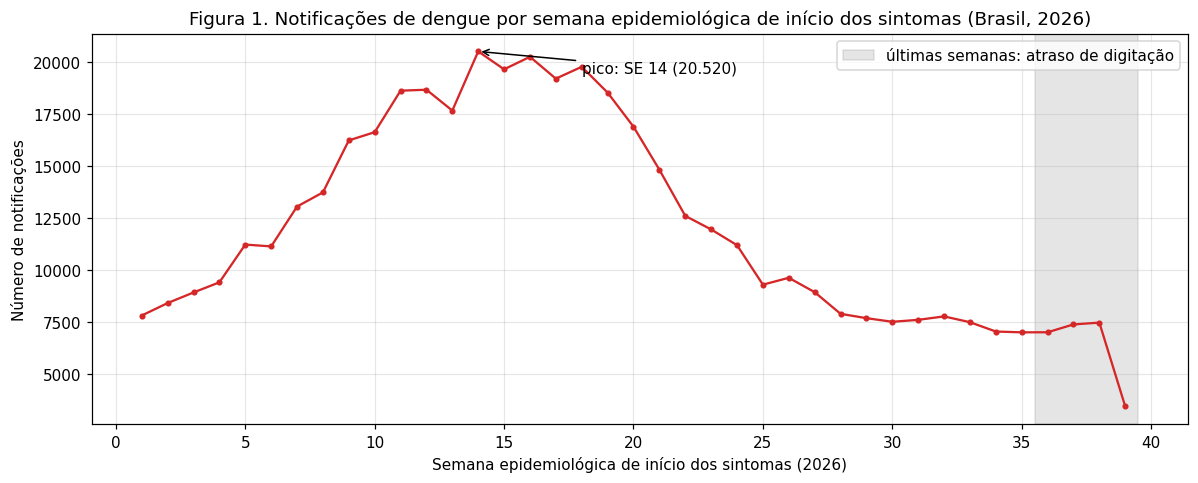

Semana de pico: 202614 com 20.520 notificações
Primeira semana (SE 01): 7.814 notificações
Menor valor entre as SE 11 e 19: 17.673
Média semanal: 12.057 | mediana semanal: 11.139
Semanas necessárias para somar 50% das notificações: 13 de 39
Semanas com mais notificações: 14, 16, 18, 15, 17
Últimas semanas:


,notificações
semana_epi_sintomas,
202634,7044
202635,7005
202636,7009
202637,7386
202638,7472
202639,3440


In [4]:
semanal = (
    df.dropna(subset=["semana_epi_sintomas"])
    .loc[lambda d: d["semana_epi_sintomas"].str.startswith("2026")]
    .groupby("semana_epi_sintomas")
    .size()
)
semanas = semanal.index.str[-2:].astype(int)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(semanas, semanal.values, marker="o", markersize=3, color="tab:red")
ultimas = semanas[-SEMANAS_COM_ATRASO_DE_DIGITACAO:]
ax.axvspan(ultimas.min() - 0.5, ultimas.max() + 0.5, color="grey", alpha=0.2, label="últimas semanas: atraso de digitação")
pico = semanal.idxmax()
ax.annotate(f"pico: SE {pico[-2:]} ({milhar(semanal.max())})", xy=(int(pico[-2:]), semanal.max()),
            xytext=(int(pico[-2:]) + 4, semanal.max() * 0.95), arrowprops={"arrowstyle": "->"})
ax.set_title("Figura 1. Notificações de dengue por semana epidemiológica de início dos sintomas (Brasil, 2026)")
ax.set_xlabel("Semana epidemiológica de início dos sintomas (2026)")
ax.set_ylabel("Número de notificações")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig1_notificacoes_por_semana.png")
plt.show()

print(f"Semana de pico: {pico} com {milhar(semanal.max())} notificações")
print(f"Primeira semana (SE 01): {milhar(semanal.iloc[0])} notificações")
print(f"Menor valor entre as SE 11 e 19: {milhar(semanal.loc['202611':'202619'].min())}")
print(f"Média semanal: {milhar(semanal.mean())} | mediana semanal: {milhar(semanal.median())}")
top = semanal.sort_values(ascending=False)
acumulado = top.cumsum() / semanal.sum()
print(f"Semanas necessárias para somar 50% das notificações: {int((acumulado < 0.5).sum()) + 1} de {len(semanal)}")
print(f"Semanas com mais notificações: {', '.join(top.index[:5].str[-2:])}")
print("Últimas semanas:")
display(semanal.tail(6).to_frame("notificações"))

**Figura 1.** As notificações sobem de 7.814 na SE 1 até o pico na semana epidemiológica 14, no início de abril, com 20.520 notificações. Da SE 11 à SE 19 ficam acima de 17.000 por semana. As cinco semanas com mais notificações são as SE 14 a 18, e só 13 das 39 semanas somam metade das notificações do ano. É o padrão sazonal da dengue, com pico no fim do verão e no outono. A partir de julho a curva fica estável em torno de 7.000 por semana. A queda na SE 39 (3.440) não quer dizer que a epidemia acabou. Essas são as semanas mais recentes do arquivo e muitas fichas ainda não foram digitadas, por isso marcamos a área em cinza. Com isso respondemos a P1: o pico foi em abril.

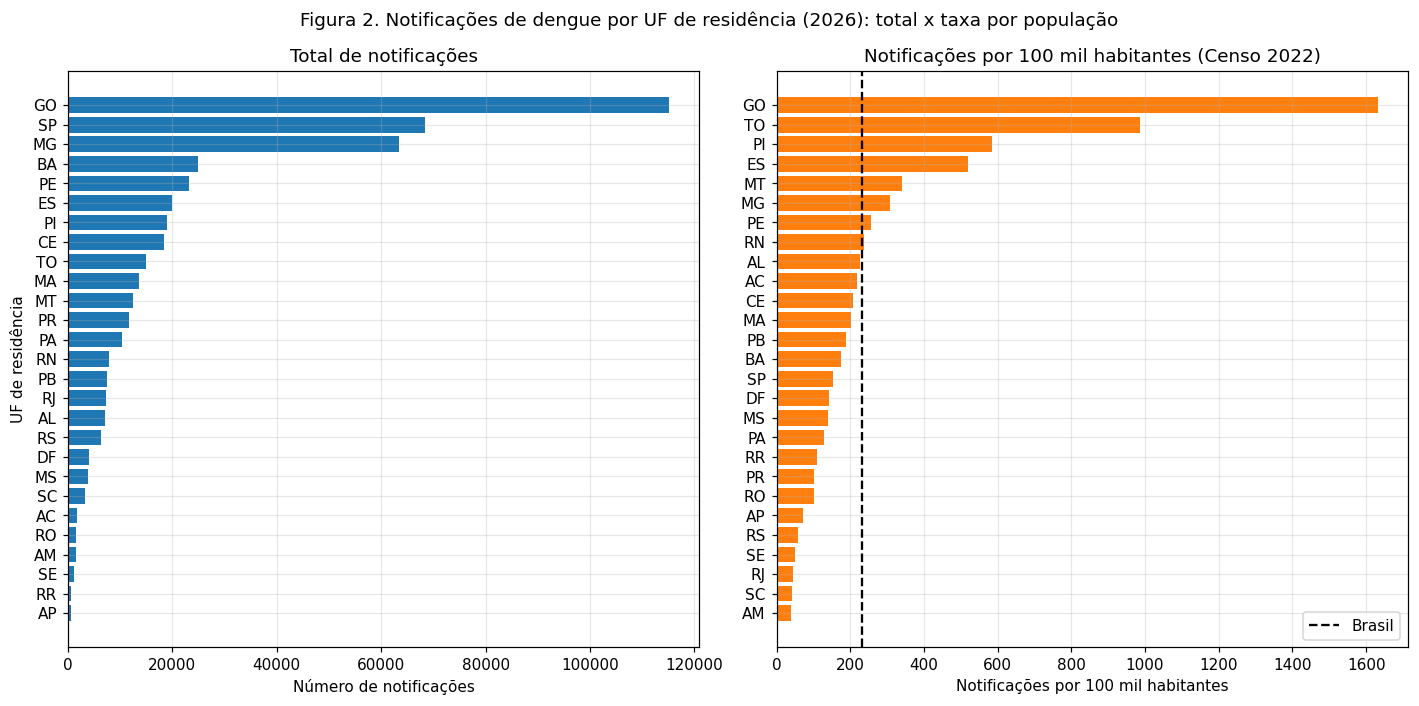

Taxa Brasil: 231.5 notificações por 100 mil habitantes
Participação das 3 UFs com mais notificações: 52,5%


,notificacoes,populacao_censo_2022,por_100_mil
uf,,,
GO,115161,7056495,"1,631.99"
SP,68330,44411238,153.86
MG,63367,20539989,308.51
BA,24856,14141626,175.76
PE,23254,9058931,256.70


,notificacoes,populacao_censo_2022,por_100_mil
uf,,,
GO,115161,7056495,"1,631.99"
TO,14918,1511460,986.99
PI,19089,3271199,583.55
ES,19944,3833712,520.23
MT,12447,3658649,340.21


,notificacoes,populacao_censo_2022,por_100_mil
uf,,,
AM,1585,3941613,40.21
SC,3287,7610361,43.19
RJ,7394,16055174,46.05


In [5]:
populacao = pd.read_csv(ARQUIVO_POPULACAO, dtype={"codigo_uf": str})
por_uf = (
    df["uf_residencia"].value_counts().rename("notificacoes").rename_axis("uf").reset_index()
    .merge(populacao[["uf", "populacao_censo_2022"]], on="uf")
)
por_uf["por_100_mil"] = por_uf["notificacoes"] / por_uf["populacao_censo_2022"] * 100_000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.5))
absoluto = por_uf.sort_values("notificacoes")
ax1.barh(absoluto["uf"], absoluto["notificacoes"], color="tab:blue")
ax1.set_title("Total de notificações")
ax1.set_xlabel("Número de notificações")
ax1.set_ylabel("UF de residência")
taxa = por_uf.sort_values("por_100_mil")
ax2.barh(taxa["uf"], taxa["por_100_mil"], color="tab:orange")
ax2.axvline(df["uf_residencia"].notna().sum() / populacao["populacao_censo_2022"].sum() * 100_000,
            color="black", linestyle="--", label="Brasil")
ax2.set_title("Notificações por 100 mil habitantes (Censo 2022)")
ax2.set_xlabel("Notificações por 100 mil habitantes")
ax2.legend()
fig.suptitle("Figura 2. Notificações de dengue por UF de residência (2026): total x taxa por população")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig2_notificacoes_por_uf.png")
plt.show()

taxa_brasil = df["uf_residencia"].notna().sum() / populacao["populacao_censo_2022"].sum() * 100_000
print(f"Taxa Brasil: {taxa_brasil:.1f} notificações por 100 mil habitantes")
print(f"Participação das 3 UFs com mais notificações: {percentual(absoluto['notificacoes'].tail(3).sum(), por_uf['notificacoes'].sum())}")
display(por_uf.sort_values("notificacoes", ascending=False).head(5).set_index("uf"))
display(por_uf.sort_values("por_100_mil", ascending=False).head(5).set_index("uf"))
display(por_uf.sort_values("por_100_mil").head(3).set_index("uf"))

**Figura 2.** Em número absoluto, Goiás (115.161), São Paulo (68.330) e Minas Gerais (63.367) somam 52,5% das notificações. Só que o número absoluto mistura o tamanho da população com a intensidade da epidemia, então no painel da direita dividimos pela população do Censo 2022. Na taxa, São Paulo cai para 153,9 notificações por 100 mil habitantes e fica abaixo da taxa nacional (231,5). Goiás tem 1.632 por 100 mil, sete vezes a média do país, e depois vêm Tocantins (987), Piauí (584) e Espírito Santo (520). As menores taxas são do Amazonas (40,2), de Santa Catarina (43,2) e do Rio de Janeiro (46,1). Por isso usamos a taxa por habitante para comparar estados. Nas duas medidas Goiás foi o estado mais atingido em 2026.

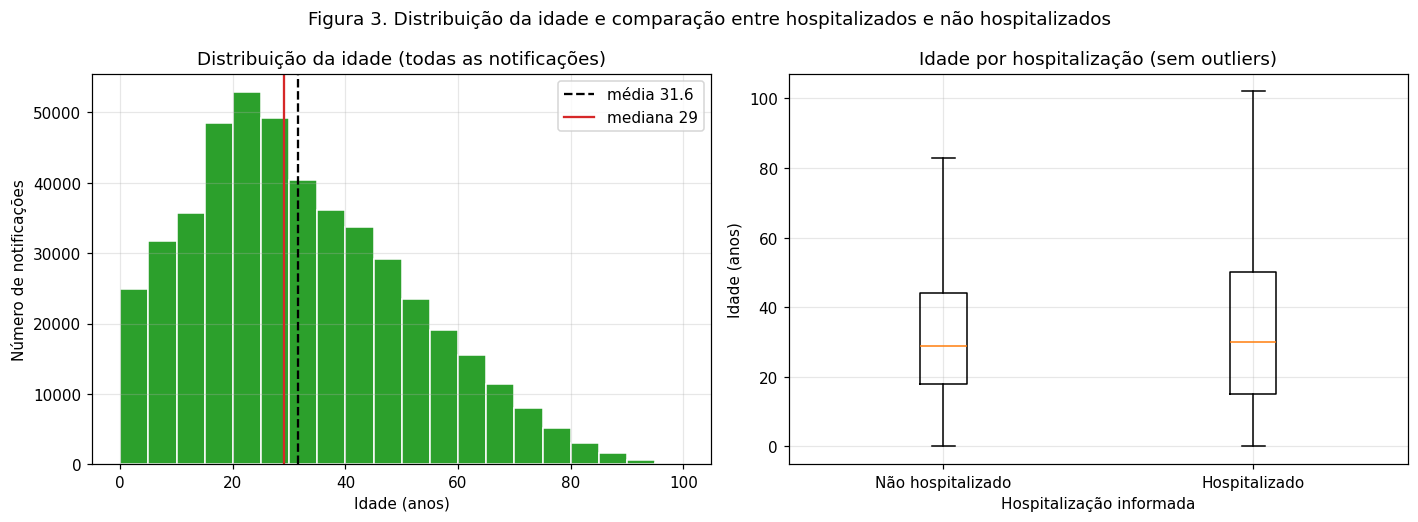

,Não hospitalizado,Hospitalizado
n válidos,"316,925.00","29,690.00"
média,31.68,33.72
mediana,29.00,30.00
Q1 (25%),18.00,15.00
Q3 (75%),44.00,50.00
IQR (Q3 - Q1),26.00,35.00


In [6]:
com_hosp = df.dropna(subset=["hospitalizado", "idade_anos"])
grupos = {
    "Não hospitalizado": com_hosp.loc[~com_hosp["hospitalizado"].astype(bool), "idade_anos"].astype(float),
    "Hospitalizado": com_hosp.loc[com_hosp["hospitalizado"].astype(bool), "idade_anos"].astype(float),
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.hist(df["idade_anos"].dropna().astype(float), bins=range(0, 105, 5), color="tab:green", edgecolor="white")
ax1.axvline(df["idade_anos"].mean(), color="black", linestyle="--", label=f"média {df['idade_anos'].mean():.1f}")
ax1.axvline(df["idade_anos"].median(), color="tab:red", label=f"mediana {df['idade_anos'].median():.0f}")
ax1.set_title("Distribuição da idade (todas as notificações)")
ax1.set_xlabel("Idade (anos)")
ax1.set_ylabel("Número de notificações")
ax1.legend()
ax2.boxplot(list(grupos.values()), tick_labels=list(grupos.keys()), showfliers=False)
ax2.set_title("Idade por hospitalização (sem outliers)")
ax2.set_xlabel("Hospitalização informada")
ax2.set_ylabel("Idade (anos)")
fig.suptitle("Figura 3. Distribuição da idade e comparação entre hospitalizados e não hospitalizados")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig3_idade_hospitalizacao.png")
plt.show()

display(pd.DataFrame({nome: medidas(serie) for nome, serie in grupos.items()}).loc[["n válidos", "média", "mediana", "Q1 (25%)", "Q3 (75%)", "IQR (Q3 - Q1)"]])

**Figura 3.** O histograma mostra a mesma assimetria à direita que vimos na 3.1. A maior parte dos pacientes tem entre 15 e 30 anos e a frequência cai depois dos 40, com a média (31,6) à direita da mediana (29). No boxplot a mediana de idade é quase a mesma entre hospitalizados (30 anos) e não hospitalizados (29 anos), mas a caixa dos hospitalizados é bem mais larga. O IQR deles é de 35 anos (de 15 a 50), contra 26 anos (de 18 a 44) nos não hospitalizados. Ou seja, internar não depende só de ser mais velho. As internações aparecem mais nas duas pontas, em crianças e em idosos, e a Figura 4 mostra isso melhor.

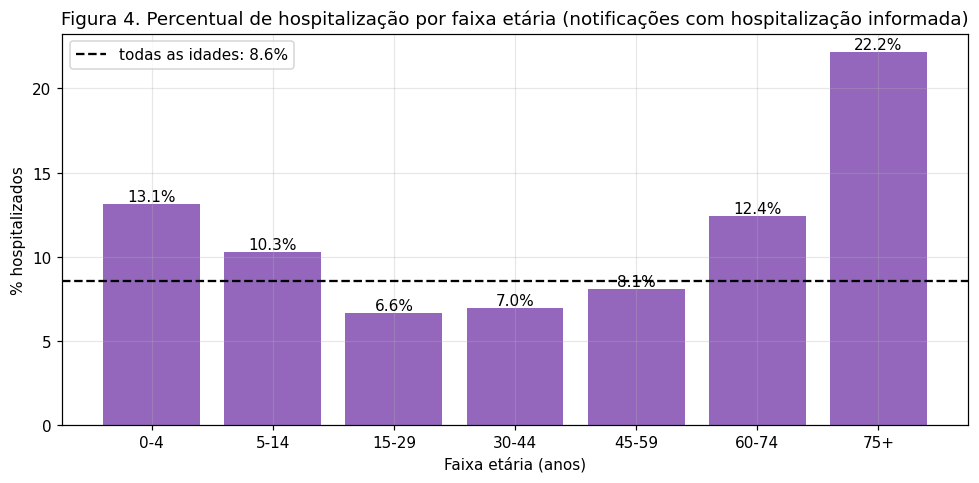

,notificacoes,hospitalizados,% hospitalizados
faixa_etaria,,,
0-4,17610,2311,13.12
5-14,48960,5022,10.26
15-29,111020,7379,6.65
30-44,81823,5697,6.96
45-59,53191,4293,8.07
60-74,26111,3238,12.40
75+,7900,1750,22.15


In [7]:
taxa_faixa = (
    df.dropna(subset=["hospitalizado", "faixa_etaria"])
    .groupby("faixa_etaria", observed=True)["hospitalizado"]
    .agg(notificacoes="size", hospitalizados="sum")
)
taxa_faixa["% hospitalizados"] = taxa_faixa["hospitalizados"] / taxa_faixa["notificacoes"] * 100
geral = df["hospitalizado"].dropna().mean() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.bar(taxa_faixa.index.astype(str), taxa_faixa["% hospitalizados"], color="tab:purple")
ax.bar_label(barras, fmt="%.1f%%")
ax.axhline(geral, color="black", linestyle="--", label=f"todas as idades: {geral:.1f}%")
ax.set_title("Figura 4. Percentual de hospitalização por faixa etária (notificações com hospitalização informada)")
ax.set_xlabel("Faixa etária (anos)")
ax.set_ylabel("% hospitalizados")
ax.legend()
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig4_hospitalizacao_por_faixa.png")
plt.show()
display(taxa_faixa)

**Figura 4.** O percentual de hospitalização forma um "U". É de 13,1% nas crianças de 0 a 4 anos e de 10,3% entre 5 e 14 anos. Cai para cerca de 7% entre 15 e 44 anos (6,7% e 7,0%) e volta a subir depois dos 45: 8,1% de 45 a 59, 12,4% de 60 a 74 e 22,2% acima de 75 anos, mais que o dobro da média geral (8,6%). Os adultos jovens são a maioria dos casos (Figura 3), mas quem mais interna são as crianças pequenas e os idosos. Isso responde em parte a P3 e mostra quais grupos a rede de saúde precisa acompanhar mais de perto. Para o modelo, significa que a relação entre idade e hospitalização não é linear.

**Resposta do grupo:**

Cada gráfico respondeu uma parte do problema. A Figura 1 mostra o tempo: o pico foi na SE 14 (20.520 notificações) e metade do ano se concentrou em 13 semanas entre março e maio. A queda no final vem do atraso de digitação. A Figura 2 mostra o espaço. Goiás lidera em número absoluto e em taxa (1.632 por 100 mil), enquanto São Paulo é o 2º em total mas fica abaixo da média nacional quando dividimos pela população. Comparar UFs só faz sentido por habitante.

As Figuras 3 e 4 tratam das pessoas. A maioria dos pacientes é adulto jovem, mas a idade dos hospitalizados é bem mais espalhada (IQR de 35 contra 26 anos), e a hospitalização segue um "U", maior em crianças até 4 anos (13,1%) e em idosos acima de 75 (22,2%).

Juntando os gráficos, conseguimos dizer quando (abril), onde (Goiás, Tocantins, Piauí e Espírito Santo) e quem mais interna (as pontas da faixa etária).

## 3.3 – Amostragem e Representatividade

- Descreva a origem e a abrangência dos dados.
- Analise em que medida o conjunto representa o contexto investigado.
- Identifique possíveis vieses ou limitações.
- Descreva o procedimento de amostragem, caso tenha sido utilizado.

Não é obrigatório implementar uma técnica de amostragem. Documente a análise principalmente em células Markdown; a célula de código abaixo é opcional, para análises complementares.

**Resposta do grupo:**

Os dados vêm do arquivo público `DENGBR26.csv.zip` do Sinan/Dengue, no Portal de Dados Abertos do SUS. O Sinan é um sistema de vigilância passiva. Um registro só existe quando o paciente é atendido, o serviço de saúde suspeita de dengue e preenche a ficha de notificação compulsória. Por isso cada linha é uma notificação, e não um caso confirmado nem uma pessoa.

O arquivo cobre as 27 UFs, com notificações de 04/01 a 04/10/2026, e tem 470.221 registros depois da preparação do RA1. Não fizemos amostragem na estatística descritiva nem nos gráficos, usamos todas as notificações do arquivo. No modelo da seção 3.4 também usamos todos os registros com hospitalização preenchida, e a única seleção é a divisão aleatória e estratificada de 80/20 entre treino e teste.

Achamos que o conjunto representa bem os casos que chegam à rede de saúde e a evolução da epidemia no tempo e entre estados, que é o que as perguntas P1, P2 e P3 investigam. Ele não representa todas as infecções de dengue da população, pelos motivos abaixo.

1. Existe subnotificação. Quem tem infecção assintomática ou leve e não procura atendimento nunca entra no Sinan, então os números são um piso e não o total real.
2. Cada estado notifica com intensidade e qualidade diferentes. Taxas muito baixas, como as de AM, SC e RJ, podem ser menos dengue ou menos notificação. A taxa por 100 mil corrige o tamanho da população, mas não corrige isso.
3. Há atraso de digitação e de encerramento. As últimas semanas estão incompletas (Figura 1) e as notificações sem classificação final passam de 1,1% nos casos de junho para 35,5% em agosto, 65,9% em setembro e 86,2% em outubro (tabela abaixo). O que dissermos sobre o segundo semestre é provisório.
4. Muitos campos estão vazios. A hospitalização falta em 26,3% das notificações e a evolução em 28,6%. A falta muda por região, de 19,0% no Centro-Oeste a 46,2% no Sul. Então o percentual de 8,6% de hospitalizados e o modelo valem para as notificações em que o campo foi preenchido.
5. O arquivo público não tem nenhuma notificação classificada como "descartado" (código 5), e 14,9% estão como inconclusivas. A base tem casos confirmados, inconclusivos ou ainda em investigação, e não todos os suspeitos que foram notificados.
6. Não existe identificador de paciente, então mantivemos as 5.797 linhas que o RA1 marcou como possível duplicata (`possivel_duplicata`). A mesma pessoa pode aparecer mais de uma vez.

Com isso, os dados servem para descrever o padrão da epidemia notificada e comparar grupos. Já os números absolutos e as regiões com muitos campos vazios devem ser lidos como estimativas conservadoras.

In [8]:
colunas = ["hospitalizado", "classificacao_final", "sexo", "idade_anos", "dt_sintomas", "uf_residencia", "diabetes", "hipertensao", "evolucao"]
completude = pd.DataFrame({
    "% vazio": df[colunas].isna().mean() * 100,
})
completude.loc["classificacao_final", "% vazio"] = (df["classificacao_final"] == "Sem classificação").mean() * 100
display(completude.sort_values("% vazio", ascending=False))

print("Hospitalização sem informação por região de residência (%):")
display((df.groupby("regiao_residencia", observed=True)["hospitalizado"].apply(lambda s: s.isna().mean() * 100)).round(1).to_frame("% vazio"))

mensal = df.groupby("mes_sintomas")["classificacao_final"].apply(lambda s: (s == "Sem classificação").mean() * 100)
print("Notificações ainda sem classificação final, por mês de início dos sintomas (%):")
display(mensal.round(1).to_frame("% sem classificação").tail(6))

print(f"Linhas marcadas como possível duplicata no RA1 (mesma chave de pessoa, local e datas): {milhar(int(df['possivel_duplicata'].sum()))}")
descartados = int((df["classificacao_final"] == "Descartado").sum())
inconclusivos = int((df["classificacao_final"] == "Inconclusivo").sum())
print(f"Notificações descartadas (código 5) no arquivo público: {milhar(descartados)}")
print(f"Notificações inconclusivas (código 8): {milhar(inconclusivos)} ({percentual(inconclusivos, len(df))})")

,% vazio
evolucao,28.59
hospitalizado,26.29
classificacao_final,7.41
hipertensao,3.17
diabetes,3.17
sexo,0.06
idade_anos,0.00
dt_sintomas,0.00
uf_residencia,0.00


Hospitalização sem informação por região de residência (%):


,% vazio
regiao_residencia,
Centro-Oeste,19.00
Nordeste,37.60
Norte,29.20
Sudeste,20.50
Sul,46.20


Notificações ainda sem classificação final, por mês de início dos sintomas (%):


,% sem classificação
mes_sintomas,
2026-05,0.50
2026-06,1.10
2026-07,3.80
2026-08,35.50
2026-09,65.90
2026-10,86.20


Linhas marcadas como possível duplicata no RA1 (mesma chave de pessoa, local e datas): 5.797
Notificações descartadas (código 5) no arquivo público: 0
Notificações inconclusivas (código 8): 69.873 (14,9%)


A tabela confirma os itens 3, 4 e 5. Quase não há vazios em sexo, idade, data e UF, mas faltam muitos dados de hospitalização e evolução, que dependem de alguém acompanhar o caso depois da notificação.

## 3.4 – Aplicação de Machine Learning

Implemente uma aplicação simples de aprendizagem supervisionada. Escolha **classificação OU regressão**, conforme a natureza do problema.

1. **Problema preditivo:** defina o que a equipe pretende prever.
2. **Entradas e alvo:** identifique as características (*features*) e a variável-alvo (*target*).
3. **Treinamento e teste:** separe os dados para treinar e avaliar o modelo.
4. **Treinamento e previsões:** treine o modelo escolhido e realize previsões.
5. **Avaliação:** utilize pelo menos uma métrica adequada ao problema.
6. **Interpretação:** explique o significado dos resultados obtidos.

A equipe pode utilizar qualquer algoritmo ou ferramenta adequada; **não é obrigatório utilizar KNN ou regressão linear**. Não é necessário implementar aprendizagem online.

Se o dataset original não for adequado à aprendizagem supervisionada, a equipe poderá utilizar outro conjunto de dados nesta seção, justificando a escolha.

**Decisões do grupo:**

O problema que escolhemos é prever, no momento da notificação, se o paciente vai ser hospitalizado. É uma classificação binária e tem uso prático, porque ajuda a identificar cedo os pacientes de maior risco para acompanhar de perto e planejar leitos.

O target é `hospitalizado` (campo `HOSPITALIZ`, 1 = sim e 2 = não). Usamos só as 346.623 notificações com o campo preenchido. Os 123.598 vazios ou "ignorado" ficaram de fora porque não sabemos a resposta certa deles. Os hospitalizados são a classe minoritária (8,6%).

Como features usamos 31 colunas, todas com informação que já existe quando a ficha é preenchida:

- idade (em décadas) e atraso entre sintomas e notificação (limitado a 60 dias);
- sexo feminino e gestante (`CS_GESTANT` de 1 a 4);
- 14 sinais e sintomas da ficha (`FEBRE`, `MIALGIA`, `CEFALEIA`, `EXANTEMA`, `VOMITO`, `NAUSEA`, `DOR_COSTAS`, `CONJUNTVIT`, `ARTRITE`, `ARTRALGIA`, `PETEQUIA_N`, `LEUCOPENIA`, `LACO`, `DOR_RETRO`);
- 7 comorbidades (`DIABETES`, `HEMATOLOG`, `HEPATOPAT`, `RENAL`, `HIPERTENSA`, `ACIDO_PEPT`, `AUTO_IMUNE`);
- um indicador de ficha clínica vazia e a região de residência (5 colunas *dummy*).

Sintomas e comorbidades viram 1 quando o campo é "sim" e 0 nos outros casos. O Parquet do RA1 só guardou as colunas das perguntas P1, P2 e P3, então lemos essas colunas do arquivo bruto e juntamos pela posição original da linha (`id_registro`).

Tiramos do modelo tudo o que só se sabe depois da internação ou que é consequência dela, para não ter vazamento de dados (*data leakage*). Ficaram de fora `DT_INTERNA` (data da internação), `EVOLUCAO` e `DT_OBITO` (desfecho), `CLASSI_FIN` e `CRITERIO` (a classificação final já usa a gravidade observada no acompanhamento), `DT_ENCERRA`, os sinais de alarme `ALRM_*` e `DT_ALRM` e os de gravidade `GRAV_*` e `DT_GRAV`, que costumam ser registrados durante a evolução e muitas vezes já no hospital. Também tiramos os exames de laboratório (sorologia, NS1, PCR e sorotipo), que normalmente saem depois do primeiro atendimento. Se essas colunas entrassem, o modelo acertaria olhando para a própria resposta e não serviria para prever nada.

Separamos 80% dos dados para treino (277.298) e 20% para teste (69.325). A divisão é estratificada pelo target, então as duas partes ficaram com 8,6% de hospitalizados, e usamos semente fixa (`random_state=42`) para dar sempre o mesmo resultado.

Treinamos três modelos. O primeiro é um *baseline* que sempre prevê a classe majoritária e serve de referência mínima. O principal é uma regressão logística com `class_weight="balanced"`, escolhida por ser simples e porque cada coeficiente vira uma razão de chances fácil de explicar. Também testamos uma árvore de decisão rasa (profundidade 6), que consegue pegar relações não lineares como o "U" da idade. O `class_weight="balanced"` dá mais peso aos hospitalizados no treino. Sem ele o modelo aprenderia a responder sempre "não".

Como as classes são desbalanceadas, a acurácia engana. O *baseline* acerta 91% sem encontrar nenhum hospitalizado. Por isso olhamos o recall (dos hospitalizados de verdade, quantos o modelo encontra), a precisão (dos pacientes que o modelo sinalizou, quantos estavam certos), o F1 (que combina os dois) e o ROC-AUC (se o modelo coloca quem interna com risco maior do que quem não interna, sem depender do limiar). Também mostramos a matriz de confusão. A métrica principal é o recall, porque o erro mais grave é deixar de sinalizar alguém que vai ser internado.

In [9]:
SINTOMAS = ["FEBRE", "MIALGIA", "CEFALEIA", "EXANTEMA", "VOMITO", "NAUSEA", "DOR_COSTAS", "CONJUNTVIT",
            "ARTRITE", "ARTRALGIA", "PETEQUIA_N", "LEUCOPENIA", "LACO", "DOR_RETRO"]
COMORBIDADES = ["DIABETES", "HEMATOLOG", "HEPATOPAT", "RENAL", "HIPERTENSA", "ACIDO_PEPT", "AUTO_IMUNE"]

# O Parquet do RA1 guarda só as colunas das perguntas P1 a P3. Sintomas, comorbidades e gestação são
# lidos do arquivo bruto e ligados pela posição da linha (id_registro), que o RA1 preservou para isso.
bruto = pd.read_csv(ARQUIVO_BRUTO, usecols=SINTOMAS + COMORBIDADES + ["CS_GESTANT"], dtype="string")
clinico = bruto.loc[df["id_registro"]].reset_index(drop=True)

base = df.reset_index(drop=True).join(clinico)
base = base[base["hospitalizado"].notna()].copy()

X = pd.DataFrame(index=base.index)
X["idade_decadas"] = base["idade_anos"].astype(float).fillna(base["idade_anos"].median()) / 10
X["atraso_dias"] = base["atraso_notificacao_dias"].astype(float).clip(0, ATRASO_EXTREMO_DIAS).fillna(base["atraso_notificacao_dias"].median())
X["sexo_feminino"] = (base["sexo"] == "Feminino").astype(int)
X["gestante"] = base["CS_GESTANT"].isin(["1", "2", "3", "4"]).astype(int)
for coluna in SINTOMAS + COMORBIDADES:
    X[coluna.lower()] = (base[coluna] == "1").astype(int)
X["ficha_clinica_vazia"] = base["FEBRE"].isna().astype(int)
X = X.join(pd.get_dummies(base["regiao_residencia"].astype("object").fillna("Sem região"), prefix="regiao", dtype=int))
y = base["hospitalizado"].astype(int)

print(f"Registros com hospitalização informada: {milhar(len(X))} (de {milhar(len(df))})")
print(f"Features: {X.shape[1]}")
print(f"Hospitalizados (classe positiva): {milhar(y.sum())} ({percentual(y.sum(), len(y))})")
print(list(X.columns))

Registros com hospitalização informada: 346.623 (de 470.221)
Features: 31
Hospitalizados (classe positiva): 29.690 (8,6%)
['idade_decadas', 'atraso_dias', 'sexo_feminino', 'gestante', 'febre', 'mialgia', 'cefaleia', 'exantema', 'vomito', 'nausea', 'dor_costas', 'conjuntvit', 'artrite', 'artralgia', 'petequia_n', 'leucopenia', 'laco', 'dor_retro', 'diabetes', 'hematolog', 'hepatopat', 'renal', 'hipertensa', 'acido_pept', 'auto_imune', 'ficha_clinica_vazia', 'regiao_Centro-Oeste', 'regiao_Nordeste', 'regiao_Norte', 'regiao_Sudeste', 'regiao_Sul']


In [10]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMENTE
)
print(f"Treino: {milhar(len(X_treino))} registros ({percentual(y_treino.sum(), len(y_treino))} hospitalizados)")
print(f"Teste:  {milhar(len(X_teste))} registros ({percentual(y_teste.sum(), len(y_teste))} hospitalizados)")

modelos = {
    "Baseline (classe majoritária)": DummyClassifier(strategy="most_frequent"),
    "Regressão logística (balanced)": LogisticRegression(class_weight="balanced", max_iter=2000),
    "Árvore de decisão (prof. 6, balanced)": DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, class_weight="balanced", random_state=SEMENTE),
}
previsoes, probabilidades = {}, {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    previsoes[nome] = modelo.predict(X_teste)
    probabilidades[nome] = modelo.predict_proba(X_teste)[:, 1]
# Teste de sensibilidade: leucopenia depende de hemograma, que pode ter sido feito já no atendimento hospitalar.
sem_leucopenia = LogisticRegression(class_weight="balanced", max_iter=2000)
sem_leucopenia.fit(X_treino.drop(columns="leucopenia"), y_treino)
nome_sens = "Regressão logística sem leucopenia"
previsoes[nome_sens] = sem_leucopenia.predict(X_teste.drop(columns="leucopenia"))
probabilidades[nome_sens] = sem_leucopenia.predict_proba(X_teste.drop(columns="leucopenia"))[:, 1]
print("Modelos treinados e previsões feitas no conjunto de teste.")

Treino: 277.298 registros (8,6% hospitalizados)
Teste:  69.325 registros (8,6% hospitalizados)


Modelos treinados e previsões feitas no conjunto de teste.


### Avaliação e interpretação

Compare as previsões com os valores reais do conjunto de teste, calcule a métrica escolhida e interprete o resultado no contexto do problema preditivo.

,acurácia,precisão,recall (sensibilidade),F1,ROC-AUC
Baseline (classe majoritária),0.914,0.000,0.000,0.000,0.500
Regressão logística (balanced),0.699,0.174,0.669,0.276,0.747
"Árvore de decisão (prof. 6, balanced)",0.678,0.168,0.698,0.271,0.744
Regressão logística sem leucopenia,0.680,0.163,0.663,0.262,0.730


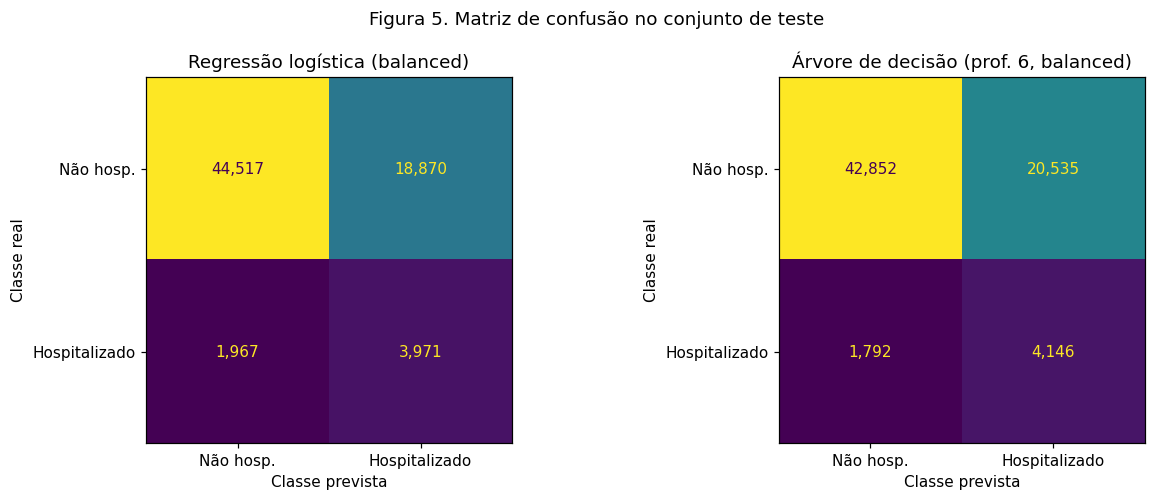

Regressão logística: VP=3.971 FN=1.967 FP=18.870 VN=44.517


In [11]:
resultados = pd.DataFrame({
    nome: {
        "acurácia": accuracy_score(y_teste, previsoes[nome]),
        "precisão": precision_score(y_teste, previsoes[nome], zero_division=0),
        "recall (sensibilidade)": recall_score(y_teste, previsoes[nome]),
        "F1": f1_score(y_teste, previsoes[nome]),
        "ROC-AUC": roc_auc_score(y_teste, probabilidades[nome]),
    }
    for nome in previsoes
}).T
display(resultados.style.format("{:.3f}"))

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, nome in zip(eixos, ["Regressão logística (balanced)", "Árvore de decisão (prof. 6, balanced)"]):
    ConfusionMatrixDisplay(confusion_matrix(y_teste, previsoes[nome]), display_labels=["Não hosp.", "Hospitalizado"]).plot(ax=ax, colorbar=False, values_format=",d")
    ax.set_title(nome)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.grid(False)
fig.suptitle("Figura 5. Matriz de confusão no conjunto de teste")
fig.tight_layout()
fig.savefig(PASTA_FIGURAS / "fig5_matriz_confusao.png")
plt.show()

vn, fp, fn, vp = confusion_matrix(y_teste, previsoes["Regressão logística (balanced)"]).ravel()
print(f"Regressão logística: VP={milhar(vp)} FN={milhar(fn)} FP={milhar(fp)} VN={milhar(vn)}")

In [12]:
logistica = modelos["Regressão logística (balanced)"]
razao_chances = pd.Series(np.exp(logistica.coef_[0]), index=X.columns, name="razão de chances").sort_values()
print("Features que mais aumentam a chance de hospitalização (razão de chances > 1):")
display(razao_chances.tail(8).sort_values(ascending=False).to_frame())
print("Features associadas a menor chance (razão de chances < 1):")
display(razao_chances.head(5).to_frame())
print("Variáveis numéricas e sexo:")
display(razao_chances[["idade_decadas", "atraso_dias", "sexo_feminino"]].to_frame())

Features que mais aumentam a chance de hospitalização (razão de chances > 1):


,razão de chances
leucopenia,4.08
gestante,2.62
regiao_Nordeste,1.91
auto_imune,1.90
renal,1.84
hematolog,1.75
vomito,1.72
diabetes,1.65


Features associadas a menor chance (razão de chances < 1):


,razão de chances
regiao_Sudeste,0.56
cefaleia,0.59
regiao_Centro-Oeste,0.63
acido_pept,0.76
conjuntvit,0.77


Variáveis numéricas e sexo:


,razão de chances
idade_decadas,1.07
atraso_dias,1.04
sexo_feminino,0.90


**Resposta do grupo:**

O *baseline* tem 91,4% de acurácia, mas recall 0 e ROC-AUC de 0,50, porque nunca identifica um hospitalizado. A regressão logística encontra 66,9% dos hospitalizados do teste (recall de 0,669), com ROC-AUC de 0,747, precisão de 0,174 e F1 de 0,276. A árvore de decisão ficou praticamente igual (recall de 0,698, F1 de 0,271 e ROC-AUC de 0,744). Escolhemos a logística porque é mais fácil de explicar.

Na matriz de confusão da logística, dos 5.938 hospitalizados do teste o modelo sinalizou 3.971 (verdadeiros positivos) e deixou passar 1.967 (falsos negativos). Em troca deu 18.870 alarmes falsos entre os 63.387 não hospitalizados. Por isso a precisão é baixa. De cada 100 pacientes sinalizados, cerca de 17 são internados de fato, o dobro da taxa geral de 8,6%.

Pelas razões de chances, o que mais aumenta a chance de internação é leucopenia (4,08 vezes), gestação (2,62), morar no Nordeste (1,91), doença autoimune (1,90), doença renal (1,84), doença hematológica (1,75), vômito (1,72) e diabetes (1,65). Isso bate com os grupos de risco que o Ministério da Saúde descreve. Morar no Sudeste (0,56) ou no Centro-Oeste (0,63) e ter cefaleia (0,59), que é um sintoma comum nos quadros leves, diminuem a chance. A idade quase não aparece na logística (1,07 por década) porque o efeito real é em "U" (Figura 4) e a regressão logística só consegue representar uma reta.

A leucopenia depende de hemograma, e esse exame pode ter sido feito já no atendimento hospitalar. Por isso treinamos de novo sem ela. O modelo perdeu pouco (ROC-AUC de 0,730 e recall de 0,663), então o resultado não depende só dessa variável.

Um ROC-AUC de 0,75 é um resultado moderado para separar quem interna de quem não interna usando só a ficha de notificação. Vemos o modelo como uma ferramenta de triagem, para decidir quem acompanhar primeiro, e não como diagnóstico. A decisão de internar depende de exames, de sinais de alarme e de ter leito, e nada disso está na notificação. O peso das regiões também indica que o modelo aprende diferenças de prática e de preenchimento entre estados, e não só risco clínico. Os 26,3% de hospitalização sem preenchimento também limitam o quanto dá para generalizar.

## 3.5 – Conclusões do RA3

Apresente brevemente:

- As principais descobertas das análises estatísticas.
- Os resultados mais relevantes das visualizações.
- A interpretação do desempenho do modelo de Machine Learning.
- As limitações identificadas.
- A relação dos resultados com o problema definido no projeto.

**Conclusões do grupo:**

O paciente típico de dengue em 2026 é um adulto jovem, com mediana de 29 anos (metade entre 17 e 44), notificado cerca de 3 dias depois dos sintomas. As duas variáveis têm assimetria à direita, então a mediana e o IQR descrevem melhor esses dados do que a média e o desvio-padrão. Formas graves (3,5% dos confirmados) e hospitalizações (8,6% das notificações com o campo preenchido) são minoria.

Pelos gráficos, a epidemia teve pico na SE 14, em abril, e metade das notificações caiu em 13 semanas. Goiás foi o estado mais atingido, com 115.161 notificações e 1.632 por 100 mil habitantes, sete vezes a taxa nacional. Na taxa vêm depois Tocantins, Piauí e Espírito Santo. O risco de internação tem forma de "U": é maior em crianças pequenas e principalmente em idosos acima de 75 anos (22,2%).

A regressão logística, usando só o que está na ficha de notificação, encontra cerca de dois terços dos pacientes que vão ser hospitalizados (recall de 0,67), com ROC-AUC de 0,75, bem acima do *baseline* (0,50). É um desempenho moderado e a precisão é baixa (0,17), o que já esperávamos com uma classe rara e poucas variáveis clínicas. As variáveis com mais peso (leucopenia, gestação, comorbidades e vômito) são os fatores de risco já conhecidos, o que nos dá mais confiança de que o modelo aprendeu padrões reais e não vazamento.

As principais limitações são a vigilância passiva com subnotificação, as diferenças de notificação entre UFs, as últimas semanas e classificações ainda incompletas, os 26,3% de hospitalização e 28,6% de evolução sem preenchimento (com diferença grande entre regiões), a falta de casos descartados no arquivo público e as possíveis duplicatas sem identificador de paciente.

Os resultados respondem às perguntas do projeto. O pico foi em abril e Goiás concentrou mais casos, tanto em número quanto por habitante (P1). Crianças pequenas, idosos, gestantes e pessoas com comorbidades têm mais chance de internar (P3). Na prática, o planejamento de leitos e de campanhas deveria se preparar para o período de março a maio e dar prioridade a esses grupos. Um modelo simples de triagem na notificação pode ajudar a sinalizar pacientes de risco, desde que o preenchimento das fichas melhore.